# 05 – Explaining the Model (SHAP)
Goal: understand which features drive churn predictions, overall and for individual customers.

In [1]:
import sys
sys.path.append("..")

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap
from sklearn.model_selection import train_test_split

from src.data import load_data
from src.features import NUMERIC_FEATURES, CATEGORICAL_FEATURES, TARGET

df = load_data("../data/raw/WA_Fn-UseC_-Telco-Customer-Churn.csv")
X = df[NUMERIC_FEATURES + CATEGORICAL_FEATURES]
y = df[TARGET]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

bundle = joblib.load("../models/churn_model.joblib")
pipe = bundle["model"]
threshold = bundle["threshold"]
print("Loaded model, threshold =", threshold)

Loaded model, threshold = 0.12


In [2]:
prep = pipe.named_steps["prep"]
clf = pipe.named_steps["model"]

feature_names = [name.split("__", 1)[1] for name in prep.get_feature_names_out()]

X_train_t = pd.DataFrame(prep.transform(X_train), columns=feature_names)
X_test_t = pd.DataFrame(prep.transform(X_test), columns=feature_names)

print(X_test_t.shape)
feature_names[:6]

(1409, 42)


['tenure',
 'MonthlyCharges',
 'SeniorCitizen',
 'Partner_No',
 'Partner_Yes',
 'Dependents_No']

In [3]:
explainer = shap.LinearExplainer(clf, X_train_t)
shap_values = explainer(X_test_t)

print(shap_values.values.shape)

Background dataset has 5634 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=5634 when initializing the masker.


(1409, 42)


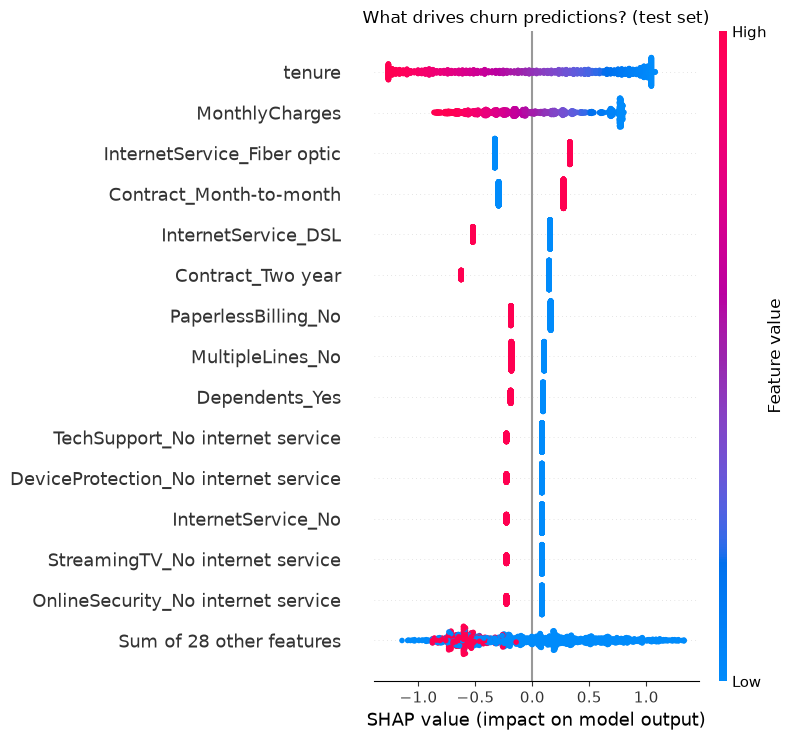

In [4]:
shap.plots.beeswarm(shap_values, max_display=15, show=False)
plt.title("What drives churn predictions? (test set)")
plt.tight_layout()
plt.show()

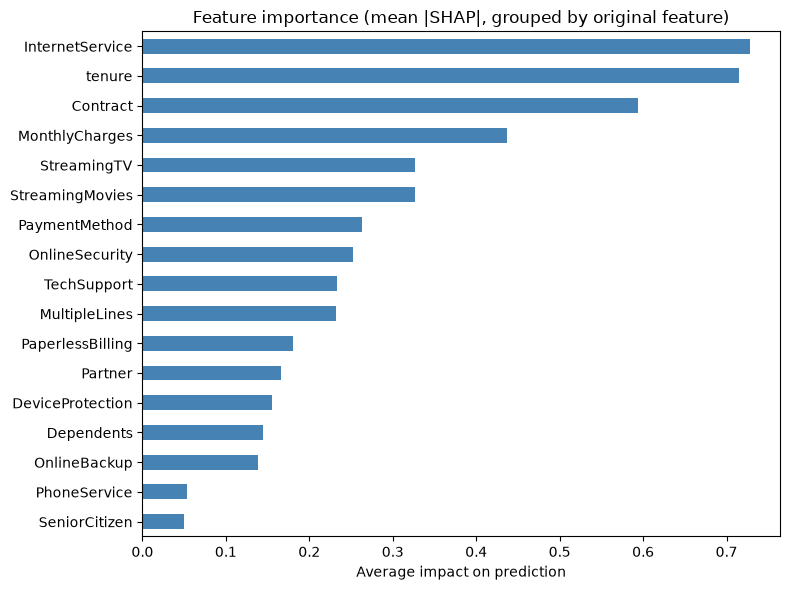

In [10]:
all_features = NUMERIC_FEATURES + CATEGORICAL_FEATURES

def original_feature(name):
    for f in all_features:
        if name == f or name.startswith(f + "_"):
            return f

mean_abs = pd.Series(np.abs(shap_values.values).mean(axis=0), index=feature_names)
importance = mean_abs.groupby(mean_abs.index.map(original_feature)).sum().sort_values()

importance.plot.barh(figsize=(8, 6), color="steelblue")
plt.title("Feature importance (mean |SHAP|, grouped by original feature)")
plt.xlabel("Average impact on prediction")
plt.tight_layout()
plt.savefig("../reports/figures/shap_importance.png", dpi=150, bbox_inches="tight")
plt.show()

### What drives churn (SHAP, test set)
- **Top drivers:** internet service type, tenure, and contract type, consistent with the EDA.
- **Raise churn risk:** fiber optic internet, month-to-month contract, short tenure (new customers).
- **Lower churn risk:** two-year contracts, long tenure, no internet service (phone-only customers).
- **Caution, correlated features:** MonthlyCharges appears to *lower* risk, the opposite of the EDA. This is because the bill is largely determined by services (fiber, streaming), which already push risk up; the model splits credit between them. SHAP explains the model, not causation, so price and services should be read together.
- The "No internet service" category is repeated across 6+ columns; merging them is a possible improvement.

In [6]:
test_proba = pipe.predict_proba(X_test)[:, 1]

i = int(np.argmax(test_proba))
print(f"Test customer #{i}: churn probability {test_proba[i]:.2f}  (threshold {threshold}) → send offer: {test_proba[i] >= threshold}")

X_test.iloc[i]

Test customer #1090: churn probability 0.87  (threshold 0.12) → send offer: True


tenure                             1
MonthlyCharges                  95.1
SeniorCitizen                      1
Partner                          Yes
Dependents                        No
PhoneService                     Yes
MultipleLines                    Yes
InternetService          Fiber optic
OnlineSecurity                    No
OnlineBackup                      No
DeviceProtection                  No
TechSupport                       No
StreamingTV                      Yes
StreamingMovies                  Yes
Contract              Month-to-month
PaperlessBilling                 Yes
PaymentMethod       Electronic check
Name: 3380, dtype: object

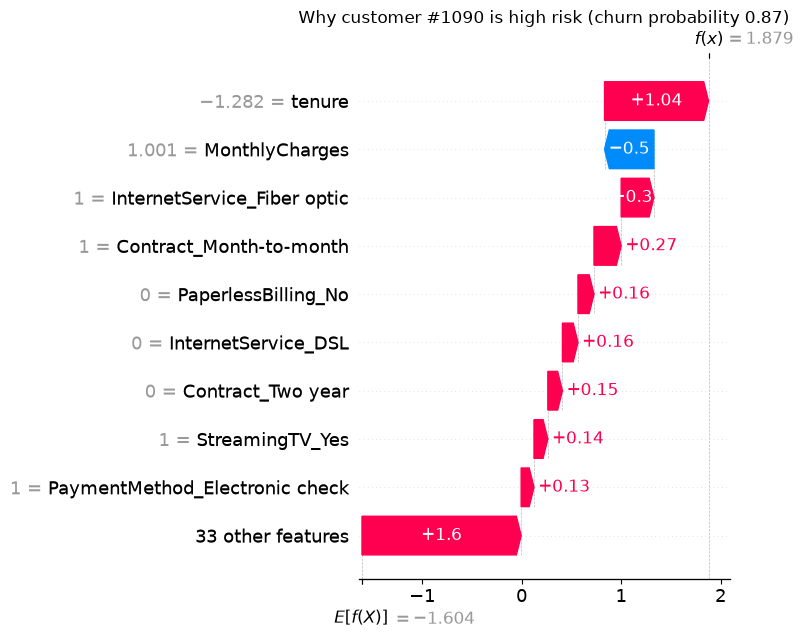

In [7]:
shap.plots.waterfall(shap_values[i], max_display=10, show=False)
plt.title(f"Why customer #{i} is high risk (churn probability {test_proba[i]:.2f})")
plt.tight_layout()
plt.show()

Test customer #955: churn probability 0.004


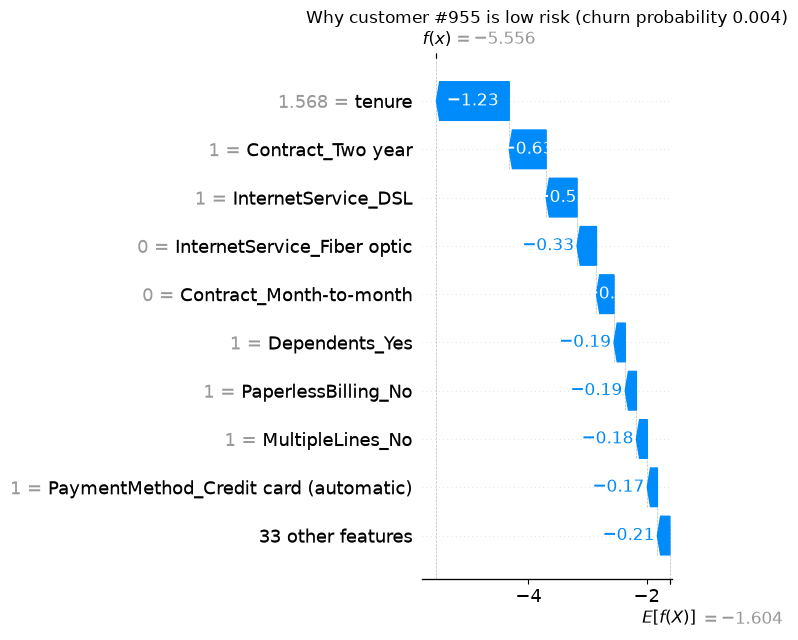

In [8]:
j = int(np.argmin(test_proba))
print(f"Test customer #{j}: churn probability {test_proba[j]:.3f}")

shap.plots.waterfall(shap_values[j], max_display=10, show=False)
plt.title(f"Why customer #{j} is low risk (churn probability {test_proba[j]:.3f})")
plt.tight_layout()
plt.show()

## Business recommendations

1. **Convert month-to-month customers to longer contracts.**
   Offer a discount for switching to a 1- or 2-year plan. Month-to-month customers churn at 43% vs 3% on two-year contracts, and contract type is a top-3 SHAP driver.

2. **Create a "first 6 months" onboarding program for new customers.**
   Welcome calls, setup help, and a check-in after the first bill. Customers in their first 6 months churn at 52.9% vs 9.5% after 4+ years, and short tenure is one of the strongest SHAP drivers. Most churn happens early, so that is where retention effort pays off most.

3. **Investigate the fiber optic experience and bundle in support services.**
   Fiber customers churn at 42% vs 19% for DSL, even though fiber is the premium product, which suggests a price or service-quality problem worth investigating. Offering free tech support or online security for the first months could help: customers without them churn at about 42%.

4. **Use the model's risk scores to target offers, with a 0.12 threshold.**
   Send retention offers to customers with predicted churn probability ≥ 0.12. On unseen test customers this catches 93% of churners and costs $11,120 (12.7%) less than the default 0.5 threshold. Review the threshold whenever offer costs or success rates change.